# Compare event-implied depths using the 2σ catalogs

Compare NOAA with ACCESS-CM2 Historical during 1990–2010, using the exact
2σ component catalogs. The compact, audited histograms let this notebook run
on either machine without reading raw archive files. The selected sources,
wave families and fit selection remain explicit below.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.paths import DATA_DIR

DETECTION_SIGMA = 2.0
sources = [("NOAA_OLR", "observations"), ("ACCESS-CM2", "historical")]
waves = ["Kelvin", "n1ERW", "MRG", "n0EIG", "n1WIG"]
INPUT = DATA_DIR / "event_threshold_comparison/distributions_sigma2"
audit = json.loads((INPUT / "audit.json").read_text())
assert audit["status"] == "complete" and audit["detection_sigma"] == DETECTION_SIGMA
counts = pd.concat([pd.read_csv(INPUT / f"{label}_event_counts.csv.gz")
                    for label in ("noaa", "all_model")], ignore_index=True)
assert counts.detection_sigma.eq(DETECTION_SIGMA).all()
index = pd.read_csv(DATA_DIR / "event_threshold_comparison/catalog_summary.csv")
index = index.loc[index.detection_sigma.eq(DETECTION_SIGMA)]
selected_index = pd.concat([index.loc[index.model.eq(model) & index.experiment.eq(experiment)]
                            for model, experiment in sources], ignore_index=True)
assert len(selected_index) == len(sources)*len(waves)
display(selected_index[["model", "experiment", "member", "wave", "run_id", "candidates", "screened_events"]])


,model,experiment,member,wave,run_id,candidates,screened_events
0,NOAA_OLR,observations,not_applicable,Kelvin,7c9ff65e1f05,2573,530
1,NOAA_OLR,observations,not_applicable,n1ERW,b72652273ae8,887,117
2,NOAA_OLR,observations,not_applicable,MRG,e8ee0a49a879,2389,475
3,NOAA_OLR,observations,not_applicable,n0EIG,ce538a73993d,2989,901
4,NOAA_OLR,observations,not_applicable,n1WIG,cdafa3cb6c9a,3045,1300
5,ACCESS-CM2,historical,r1i1p1f1,Kelvin,c1d6b8115548,2666,432
6,ACCESS-CM2,historical,r1i1p1f1,n1ERW,07054a601f3a,1070,120
7,ACCESS-CM2,historical,r1i1p1f1,MRG,c1d342f230c5,2208,439
8,ACCESS-CM2,historical,r1i1p1f1,n0EIG,e6f58b2b9e28,3045,882
9,ACCESS-CM2,historical,r1i1p1f1,n1WIG,e2e0d99b7431,3277,1396


## All successful, dispersion-valid depth fits

These are event counts per 1 m bin. No normalization across sources is applied.
Depths outside 1–100 m remain in the source catalogs and in the legend's count.

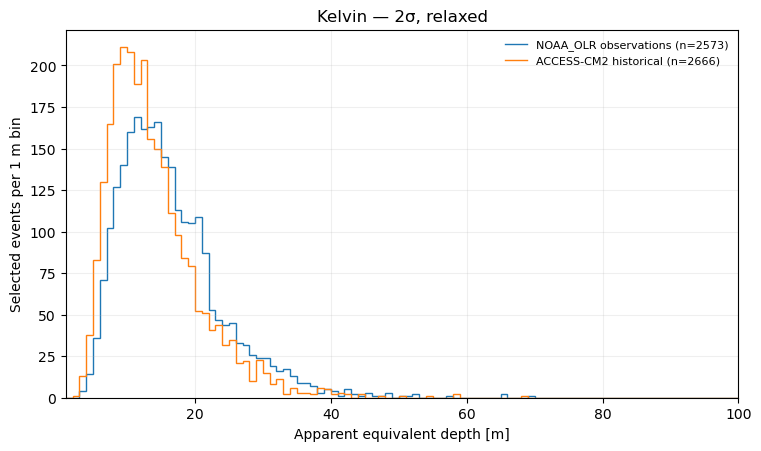

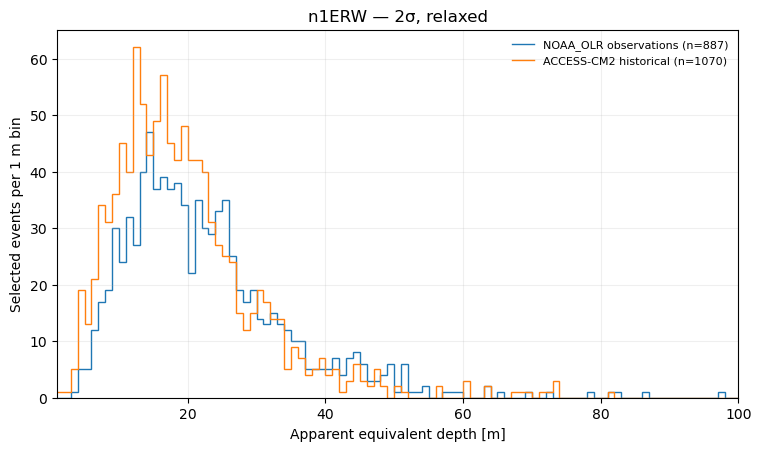

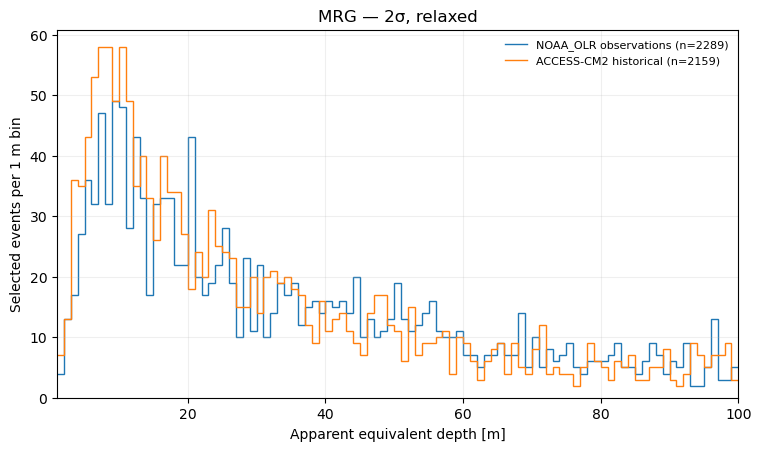

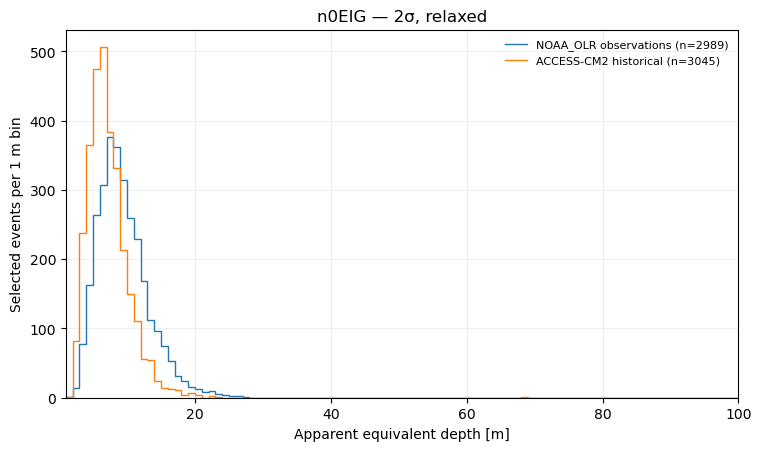

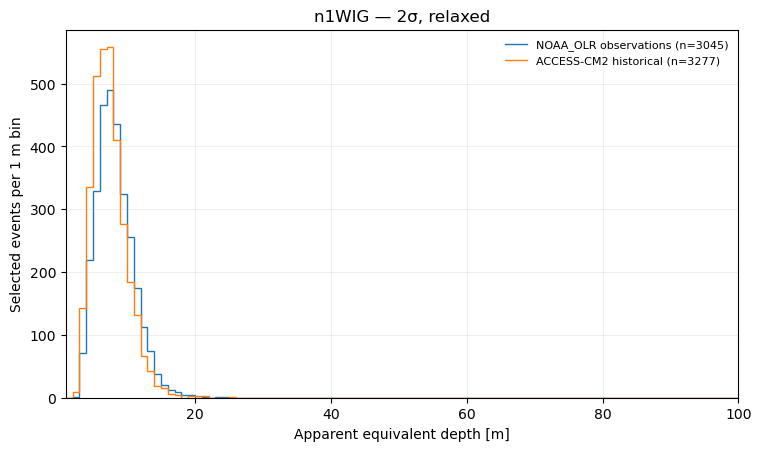

In [2]:
EDGES_M = np.arange(1.0, 101.0)
COLUMNS = [f"count_{i:03d}m" for i in range(1, 100)]

def plot_sources(selection):
    for wave in waves:
        fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
        for model, experiment in sources:
            rows = counts.loc[counts.model.eq(model) & counts.experiment.eq(experiment)
                              & counts.wave_type.eq(wave) & counts.selection.eq(selection)]
            if len(rows) != 1:
                raise ValueError(f"Expected one exact 2σ source/member: {model}/{experiment}/{wave}")
            row = rows.iloc[0]
            ax.stairs(row[COLUMNS].to_numpy(dtype=float), EDGES_M, baseline=None,
                      label=f"{model} {experiment} (n={int(row.selected_events)})")
        ax.set(xlim=(1, 100), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
               ylabel="Selected events per 1 m bin", title=f"{wave} — 2σ, {selection}")
        ax.legend(frameon=False, fontsize=8)
        ax.grid(alpha=.2)
        plt.show()

plot_sources("relaxed")


## Existing fit-quality screen

This view uses the same 2σ detections and additionally applies the existing
`keep_for_histogram` quality flags. It is not a new amplitude threshold.

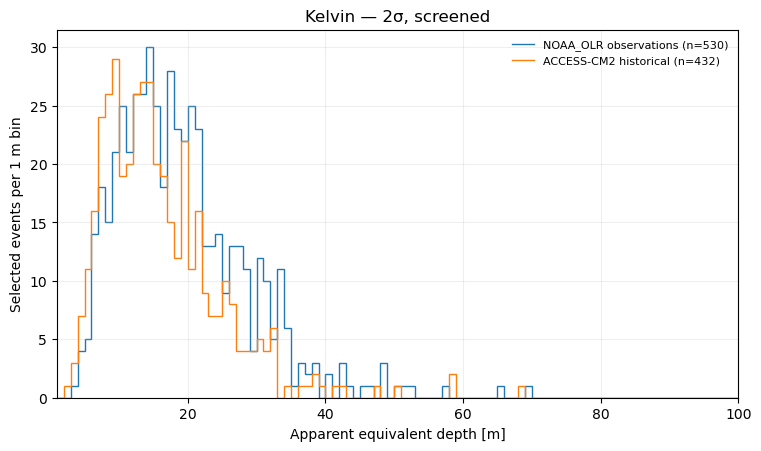

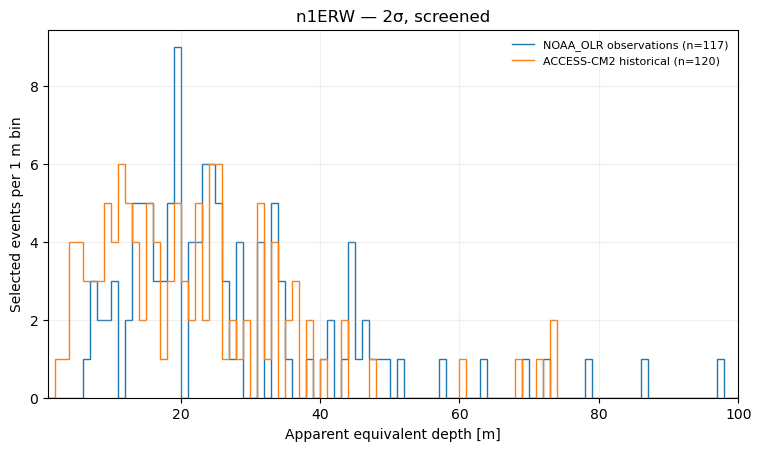

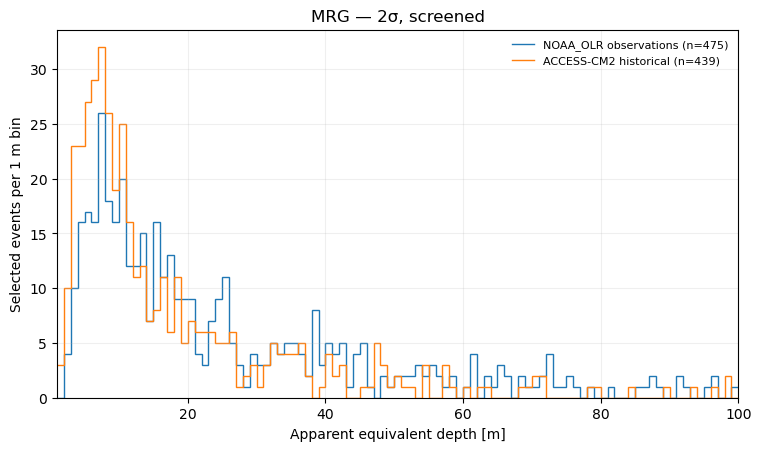

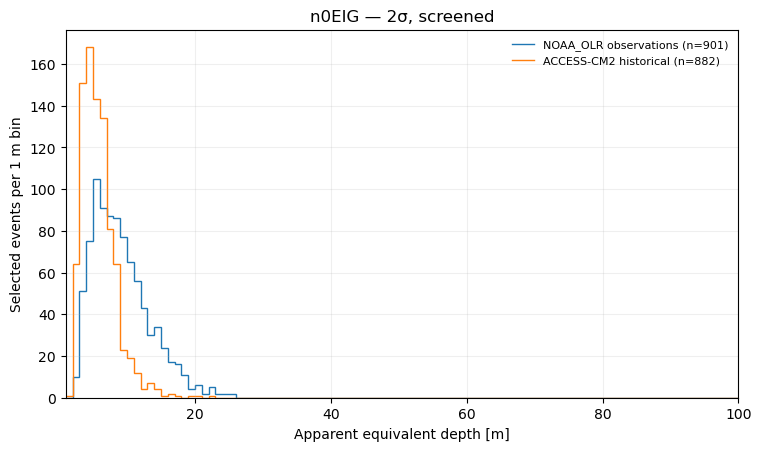

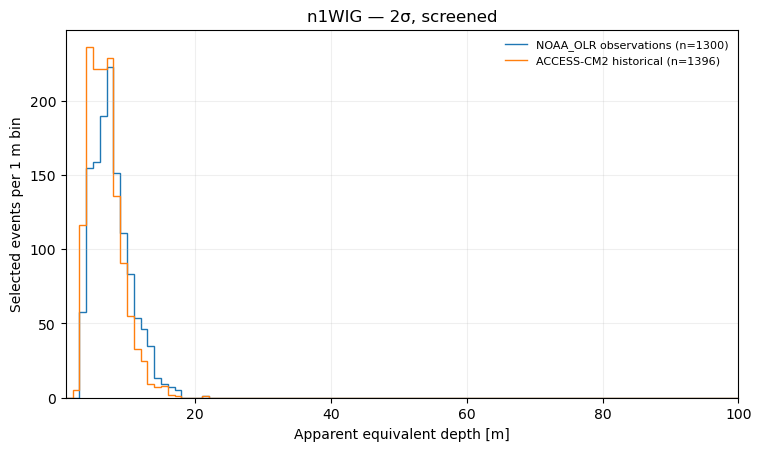

In [3]:
plot_sources("screened")


## Catalog selection

The displayed `run_id` values identify the exact 2σ catalogs for further work
with `src.wave_events.load_event_catalog` on Levante. An unqualified loader call
can match both thresholds; this notebook never selects an arbitrary newest file.
The compact counts preserve the original catalog member and native calendar.
The previous exploratory notebook is preserved in Git and the data backup.